# Sparse Sensor Placement Optimization for Classification (`SSPOC`) on NYISO DART Spreads

**Project:** NYISO `N.Y.C.` (Zone J) Day-Ahead to Real-Time (DART) Spread Virtual Bidding (`2025–2026` Out-of-Sample)  
**Prerequisite Context:** While **Iterative & Scheduled-Refit `DMDc`** adapts to seasonal and fuel regime drift (`+$24.1k` Cum PnL, `3.12` Sharpe), it requires dense, full-state observations across all grid nodes and 424 exogenous variables, and its continuous linear MSE objective yields limited tail discrimination (`0.231` Tail F1).

### Objectives of This Notebook
Following **Brunton et al. (2016)** (*Sparse Sensor Placement Optimization for Classification*), we extract a minimal subset of $p \in \{5, 10, 20, 40\}$ critical generator buses out of **559 NYISO nodes** (projected onto a rank-25 POD basis capturing `98.0%` of nodal variance) and evaluate:

1. **Sensor Placement Ablation (`SSPOC` vs. `QR-Pivoting` vs. `Mutual-Info`):** Contrasts discriminative sparse sensing (`SSPOC`) against whole-grid reconstruction (`QR-Pivoting`) and univariate correlation (`Mutual-Info`) across 5 downstream classifiers (`Multinomial Logit`, `Logit`, `GBDT`, `LDA`, and `Balanced MLP`).
2. **Physical Transmission Bottleneck Interpretability:** Maps selected PTIDs to `P-19` generator and `P-23` subzone metadata to verify whether `SSPOC` discovers upstream congestion interfaces feeding `N.Y.C.`
3. **Spatial Generalization (`LONGIL` & `HUD VL`):** Tests whether `SSPOC` dynamically relocates its bellwether sensors to match the physical bottlenecks of adjacent load pockets.
4. **Expanding Walk-Forward Sensor Stability (`2025–2026`):** Measures quarterly Jaccard persistence across 8 out-of-sample cutoffs to identify invariant core grid sensors.
5. **Cross-Paradigm Head-to-Head (`30-Day Refit SSPOC` vs. `30-Day Refit DMDc`):** Evaluates `SSPOC` ($p=20$) under the exact same **30-day (`720h`) expanding-window refit schedule** used for `DMDc` to compare sparse nodal classification against dense forced dynamical modeling.


**Load** Cached Ablation Artifacts & P-19 / P-23 Metadata

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_loader import load_data
from sparse_sensor import run_sparse_sensor_ablation

# 1. Load cached dataset (hits Parquet cache immediately if already built)
data = load_data(force_refresh_active=False)

# 2. Run or load cached sparse sensor ablation for N.Y.C. (Zone J)
ablation = run_sparse_sensor_ablation(
    data=data,
    target_zone="N.Y.C.",
    p_budgets=(5, 10, 20, 40),
    pod_rank=25,
    sspoc_alpha_frac= 0.15,
    force_recompute=False,
)

metrics_df = ablation["metrics_df"]
recon_df = ablation["recon_df"]
sensors = ablation["selected_sensors"]
meta = ablation["meta"]

print(f"Total Generator Nodes: {meta['n_nodes_total']} | POD Rank-{meta['pod_rank']} Energy: {meta['pod_energy_captured']*100:.1f}%")
display(recon_df.pivot(index="p", columns="Scheme", values=["Grid R2", "Grid RMSE ($/MWh)"]))


P-54B (rt_actual_outages) [83/83 cached]: 100%|██████████| 83/83 [00:00<00:00, 1465.26zip/s]
P-511A (dam_limiting_constraints) [249/249 cached]: 100%|██████████| 249/249 [00:00<00:00, 5163.97zip/s]
P-27 (dam_bid_data) [474/474 cached]: 100%|██████████| 474/474 [00:00<00:00, 2933.42zip/s]


[CACHE HIT] Loading dam_lbmp_gen.parquet...
[CACHE HIT] Loading rt_int_lbmp_gen.parquet...
[CACHE HIT] Loading dam_lbmp_zone.parquet...
[CACHE HIT] Loading rt_int_lbmp_zone.parquet...
[CACHE HIT] Loading iso_load_forecast.parquet...
[CACHE HIT] Loading weather_forecast.parquet...
[CACHE HIT] Loading zonal_bid_load.parquet...
[CACHE HIT] Loading btm_solar_forecast.parquet...
[CACHE HIT] Loading rt_int_actual_load.parquet...
[CACHE HIT] Loading dam_sched_outages.parquet...
[CACHE HIT] Loading rt_actual_outages.parquet...
[CACHE HIT] Loading dam_limiting_constraints.parquet...
[CACHE HIT] Loading rt_fuel_mix.parquet...
[CACHE HIT] Loading interface_flows.parquet...
[CACHE HIT] Partitioned dataset ready at nyiso_data/merged_parquet/dam_bid_data/...
[CACHE HIT] Loading nodal_dart_spread.parquet & labels...
[CACHE HIT] Loading zonal_dart_spread.parquet & labels...
[CACHE HIT] Loading exogenous_features.parquet...

=== Pipeline Complete ===
Nodal DART Matrix:      (59958, 559) (Timestamps x G

Grid R2                     Grid RMSE ($/MWh)                   
Scheme Mutual-Info QR-Pivoting   SSPOC       Mutual-Info QR-Pivoting  SSPOC
p                                                                          
5           0.2896      0.0281  0.0464             36.11       42.95  43.11
10          0.2880      0.0954  0.0746             36.24       41.79  42.70
20          0.0612      0.4057  0.1364             40.47       34.72  42.05
40         -0.2293      0.9454  0.1957             50.77       11.14  40.57

In [2]:
metrics_df

,Scheme,p,Model,Macro F1,Tail F1,Trades,Trade Freq (%),Win Rate (%),Avg PnL/Trade ($),Cum PnL ($),Annual Sharpe,Max DD ($)
0,QR-Pivoting,5,Multinomial Logit,0.3708,0.3073,11253,69.0,53.1,1.65,18518.72,1.69,14881.28
1,QR-Pivoting,5,GBDT,0.4484,0.3079,6570,40.3,57.2,1.99,13099.13,1.22,23865.08
2,QR-Pivoting,5,LDA,0.4062,0.2236,3927,24.1,55.8,2.60,10191.41,0.96,19250.14
3,QR-Pivoting,5,Balanced MLP,0.4143,0.2853,7495,46.0,50.2,3.10,23240.11,2.15,12421.40
4,QR-Pivoting,5,Logit (tau=0.18),0.3816,0.3103,10880,66.7,53.5,1.39,15152.82,1.38,16423.34
5,QR-Pivoting,10,Multinomial Logit,0.3722,0.3076,11200,68.7,53.3,1.59,17838.03,1.62,16288.82
6,QR-Pivoting,10,GBDT,0.4490,0.3088,6634,40.7,57.6,2.36,15686.13,1.43,25262.63
7,QR-Pivoting,10,LDA,0.4071,0.2248,3928,24.1,55.9,2.78,10916.46,1.03,19124.20
8,QR-Pivoting,10,Balanced MLP,0.3936,0.2720,8246,50.6,48.9,-0.32,-2608.35,-0.24,27038.56
9,QR-Pivoting,10,Logit (tau=0.20),0.3940,0.3094,10132,62.1,53.6,1.77,17890.51,1.63,14913.24


**Join** Selected PTIDs with P-19 Generator & P-23 Subzone Metadata


In [3]:
gen_meta = data["gen_meta"].copy()
subzone_meta = data["subzone_meta"].copy()

print("P-19 Columns:", list(gen_meta.columns))
print("P-23 Columns:", list(subzone_meta.columns))

# 1. Auto-detect PTID column (or index) in P-19
if gen_meta.index.name and "ptid" in str(gen_meta.index.name).lower():
    gen_meta = gen_meta.reset_index()

ptid_col = next((c for c in gen_meta.columns if "ptid" in str(c).lower()), None)
name_col = next((c for c in gen_meta.columns if "name" in str(c).lower() and "zone" not in str(c).lower()), None)
zone_col = next((c for c in gen_meta.columns if str(c).lower().strip() in ("zone", "zone name", "load zone")), None)
subzone_col = next((c for c in gen_meta.columns if "subzone" in str(c).lower()), None)

if ptid_col is not None:
    gen_meta["PTID_str"] = gen_meta[ptid_col].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
else:
    # Fallback: extract PTID -> Name directly from P-2B parquet if P-19 schema differs
    p2b_sample = pd.read_parquet("./nyiso_data/merged_parquet/dam_lbmp_gen.parquet", columns=["PTID", "Name"]).drop_duplicates("PTID")
    p2b_sample["PTID_str"] = p2b_sample["PTID"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    gen_meta = p2b_sample.rename(columns={"Name": "Generator Name"})
    name_col = "Generator Name"

rename_map = {}
if name_col and name_col != "Generator Name":
    rename_map[name_col] = "Generator Name"
if zone_col and zone_col != "Zone Name":
    rename_map[zone_col] = "Zone Name"
if subzone_col and subzone_col != "Subzone":
    rename_map[subzone_col] = "Subzone"

gen_meta_unique = gen_meta.rename(columns=rename_map).drop_duplicates(subset=["PTID_str"]).copy()

# Merge P-23 Subzone metadata if Subzone is available
if "Subzone" in gen_meta_unique.columns:
    p23_sub_col = next((c for c in subzone_meta.columns if "subzone" in str(c).lower()), None)
    if p23_sub_col:
        sub_clean = subzone_meta.rename(columns={p23_sub_col: "Subzone"}).drop_duplicates(subset=["Subzone"])
        gen_meta_unique = gen_meta_unique.merge(sub_clean, on="Subzone", how="left", suffixes=("", "_p23"))

def build_sensor_table(scheme_name: str, top_k: int = 20) -> pd.DataFrame:
    ptids = sensors[scheme_name]["ranked_ptids"][:top_k]
    scores = sensors[scheme_name]["scores"][:top_k]
    df_sel = pd.DataFrame({
        "Rank": np.arange(1, len(ptids) + 1),
        "PTID_str": [str(p).replace(".0", "").strip() for p in ptids],
        "Selection_Score": np.round(scores, 5),
    })
    merged = df_sel.merge(gen_meta_unique, on="PTID_str", how="left")
    priority_cols = ["Rank", "PTID_str", "Generator Name", "Zone Name", "Subzone", "Selection_Score"]
    keep_cols = [c for c in priority_cols if c in merged.columns]
    return merged[keep_cols]

sspoc_top20 = build_sensor_table("SSPOC", top_k=20)
qr_top20 = build_sensor_table("QR-Pivoting", top_k=20)
mi_top20 = build_sensor_table("Mutual-Info", top_k=20)

print("\n=== Top 20 Bellwether Nodes Selected by SSPOC (Target: N.Y.C.) ===")
display(sspoc_top20)

print("\n=== Top 20 Nodes Selected by QR-Pivoting (Whole-Grid Reconstruction) ===")
display(qr_top20)


P-19 Columns: ['Generator Name', 'Generator PTID', 'Aggregation PTID', 'Subzone', 'Zone', 'Latitude', 'Longitude', 'Active']
P-23 Columns: ['Transmission Owner', 'Subzone', 'Zone']

=== Top 20 Bellwether Nodes Selected by SSPOC (Target: N.Y.C.) ===


,Rank,PTID_str,Generator Name,Zone Name,Subzone,Selection_Score
0,1,323705,HUNTINGTON_RES_REC,LONGIL,LIPA LONG ISLAND,0.64887
1,2,24207,NEG___GEN_MONROE,GENESE,NMPC GENESEE,0.33166
2,3,23744,NINE_MILE_2,CENTRL,NMPC CENTRAL,0.31196
3,4,23575,NINE_MILE_1,CENTRL,NMPC CENTRAL,0.25398
4,5,323601,HQ_GEN_IMPORT,H Q,HQNY,0.25092
5,6,323574,MAPLE_RIDGE_WT_1,MHK VL,NMPC MOHAWK VLY,0.24924
6,7,323611,MAPLE_RIDGE_WT_2,MHK VL,NMPC MOHAWK VLY,0.24920
7,8,323591,NPX_GEN_1385_PROXY,NPX,NENP,0.19642
8,9,23651,HQ_GEN_WHEEL,H Q,HQEX,0.19269
9,10,323758,CRICKET___VALLEY_CC3,HUD VL,CON ED HUDSON VLY,0.17039



=== Top 20 Nodes Selected by QR-Pivoting (Whole-Grid Reconstruction) ===


,Rank,PTID_str,Generator Name,Zone Name,Subzone,Selection_Score
0,1,323705,HUNTINGTON_RES_REC,LONGIL,LIPA LONG ISLAND,1.00000
1,2,323591,NPX_GEN_1385_PROXY,NPX,NENP,0.50000
2,3,323758,CRICKET___VALLEY_CC3,HUD VL,CON ED HUDSON VLY,0.33333
3,4,23983,CH_RES_BVR_FALLS,MHK VL,NMPC MOHAWK VLY,0.25000
4,5,23512,ARTHUR_KILL_2,N.Y.C.,CON ED NY CITY,0.20000
5,6,323617,CANDIGU_WT_PWR,CENTRL,NYSEG CENTRAL,0.16667
6,7,23641,MONGAUP___HYD,HUD VL,O&R HUDSON VLY,0.14286
7,8,23847,NEWTON___FALLS_HYD,MHK VL,NMPC MOHAWK VLY,0.12500
8,9,23659,INDIAN POINT_GT_2,MILLWD,CON ED MILLWOOD,0.11111
9,10,323621,DELAWARE___LFGE,MHK VL,NYSEG MOHAWK VLY,0.10000


**Analyze** Spatial Distribution & Bottleneck Concentration

In [4]:
def summarize_zone_allocation(top_k: int = 20) -> pd.DataFrame:
    rows = []
    for scheme in ["SSPOC", "QR-Pivoting", "Mutual-Info"]:
        tbl = build_sensor_table(scheme, top_k=top_k)
        zone_counts = tbl["Zone Name"].fillna("UNKNOWN").value_counts()
        for zone, cnt in zone_counts.items():
            rows.append({
                "Scheme": scheme,
                "Zone Name": zone,
                "Sensor Count": int(cnt),
                "Share (%)": round(cnt / top_k * 100, 1),
            })
    summary = pd.DataFrame(rows)
    return summary.pivot(index="Zone Name", columns="Scheme", values="Sensor Count").fillna(0).astype(int)

zone_dist_20 = summarize_zone_allocation(top_k=20)
print("=== Zonal Allocation of Top p=20 Sensors Across Schemes ===")
display(zone_dist_20)

# Compute Jaccard Overlap between SSPOC and QR-Pivoting across p in {5, 10, 20, 40}
overlap_rows = []
for p in [5, 10, 20, 40]:
    s_sspoc = set(sensors["SSPOC"]["ranked_ptids"][:p])
    s_qr = set(sensors["QR-Pivoting"]["ranked_ptids"][:p])
    s_mi = set(sensors["Mutual-Info"]["ranked_ptids"][:p])
    overlap_rows.append({
        "p": p,
        "SSPOC ∩ QR (Count)": len(s_sspoc & s_qr),
        "SSPOC vs QR Jaccard": round(len(s_sspoc & s_qr) / len(s_sspoc | s_qr), 3),
        "SSPOC vs MI Jaccard": round(len(s_sspoc & s_mi) / len(s_sspoc | s_mi), 3),
    })

print("\n=== Set Overlap (Jaccard Similarity) Between Sensor Schemes ===")
display(pd.DataFrame(overlap_rows))


=== Zonal Allocation of Top p=20 Sensors Across Schemes ===


Scheme,Mutual-Info,QR-Pivoting,SSPOC
Zone Name,,,
CAPITL,1,1,0
CENTRL,0,2,2
GENESE,0,0,2
H Q,0,0,2
HUD VL,9,3,5
LONGIL,0,3,1
MHK VL,0,4,2
MILLWD,0,1,0
N.Y.C.,10,1,0



=== Set Overlap (Jaccard Similarity) Between Sensor Schemes ===


,p,SSPOC ∩ QR (Count),SSPOC vs QR Jaccard,SSPOC vs MI Jaccard
0,5,1,0.111,0.000
1,10,3,0.176,0.053
2,20,5,0.143,0.053
3,40,18,0.290,0.053


**Plot** Physical Bottleneck & Transmission Corridor Grouping

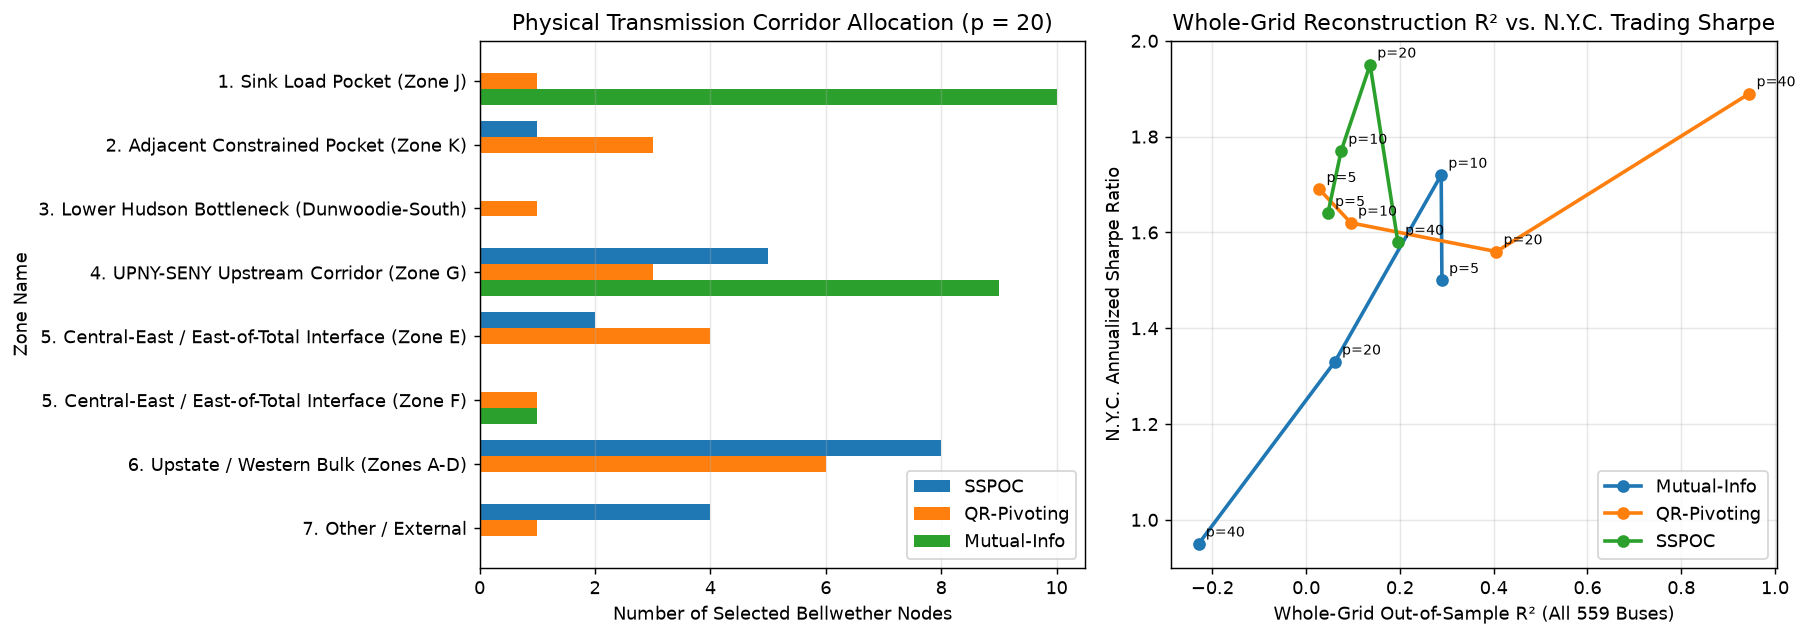

In [5]:
# Group NYISO zones into physical transmission corridors relative to N.Y.C. (Zone J)
CORRIDOR_MAP = {
    "N.Y.C.": "1. Sink Load Pocket (Zone J)",
    "LONGIL": "2. Adjacent Constrained Pocket (Zone K)",
    "DUNWOD": "3. Lower Hudson Bottleneck (Dunwoodie-South)",
    "MILLWD": "3. Lower Hudson Bottleneck (Dunwoodie-South)",
    "HUD VL": "4. UPNY-SENY Upstream Corridor (Zone G)",
    "CAPITL": "5. Central-East / East-of-Total Interface (Zone F)",
    "MHK VL": "5. Central-East / East-of-Total Interface (Zone E)",
    "CENTRL": "6. Upstate / Western Bulk (Zones A-D)",
    "NORTH": "6. Upstate / Western Bulk (Zones A-D)",
    "GENESE": "6. Upstate / Western Bulk (Zones A-D)",
    "WEST": "6. Upstate / Western Bulk (Zones A-D)",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=130)

# Plot 1: Corridor Allocation at p=20
corridor_data = {}
for scheme in ["SSPOC", "QR-Pivoting", "Mutual-Info"]:
    tbl = build_sensor_table(scheme, top_k=20)
    z_norm = tbl["Zone Name"].astype(str).str.upper().str.strip()
    corridors = z_norm.map(CORRIDOR_MAP).fillna("7. Other / External")
    corridor_data[scheme] = corridors.value_counts()

corridor_df = pd.DataFrame(corridor_data).fillna(0).sort_index()
corridor_df.plot(kind="barh", ax=axes[0], width=0.75)
axes[0].set_title("Physical Transmission Corridor Allocation (p = 20)")
axes[0].set_xlabel("Number of Selected Bellwether Nodes")
axes[0].invert_yaxis()
axes[0].grid(axis="x", alpha=0.3)

# Plot 2: Pareto Frontier — Whole-Grid R2 vs. N.Y.C. Virtual Trading Sharpe
best_trading = (
    metrics_df[metrics_df["Model"] == "Multinomial Logit"]
    .merge(recon_df, on=["Scheme", "p"])
)
for scheme, grp in best_trading.groupby("Scheme"):
    axes[1].plot(grp["Grid R2"], grp["Annual Sharpe"], marker="o", linewidth=2, label=scheme)
    for _, r in grp.iterrows():
        axes[1].annotate(f"p={int(r['p'])}", (r["Grid R2"], r["Annual Sharpe"]), fontsize=8, xytext=(4, 4), textcoords="offset points")

axes[1].set_title("Whole-Grid Reconstruction R² vs. N.Y.C. Trading Sharpe")
axes[1].set_xlabel("Whole-Grid Out-of-Sample R² (All 559 Buses)")
axes[1].set_ylabel("N.Y.C. Annualized Sharpe Ratio")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [6]:
# 1. Print Top 20 Calibrated SSPOC Bellwether Nodes for N.Y.C.
print("### 1. Top 20 SSPOC Bellwether Nodes (Target: N.Y.C.)")
print(build_sensor_table("SSPOC", top_k=20).to_markdown(index=False))

# 2. Print Whole-Grid Reconstruction Table
print("\n### 2. Whole-Grid Reconstruction (All 559 Buses)")
recon_piv = recon_df.pivot(index="p", columns="Scheme", values=["Grid R2", "Grid RMSE ($/MWh)"])
print(recon_piv.to_markdown())

# 3. Print Annual Sharpe & Cum PnL Pivot Across All Models and Sensor Budgets
print("\n### 3. N.Y.C. Out-of-Sample Annual Sharpe Across All Models")
sharpe_piv = metrics_df.pivot(index=["Model", "p"], columns="Scheme", values="Annual Sharpe")
print(sharpe_piv.to_markdown())

print("\n### 4. Top 12 Configurations Overall (Ranked by Annual Sharpe)")
top12 = metrics_df.sort_values("Annual Sharpe", ascending=False).head(12)
print(top12.to_markdown(index=False))



### 1. Top 20 SSPOC Bellwether Nodes (Target: N.Y.C.)
|   Rank |   PTID_str | Generator Name                      | Zone Name   | Subzone           |   Selection_Score |
|-------:|-----------:|:------------------------------------|:------------|:------------------|------------------:|
|      1 |     323705 | HUNTINGTON_RES_REC                  | LONGIL      | LIPA LONG ISLAND  |           0.64887 |
|      2 |      24207 | NEG___GEN_MONROE                    | GENESE      | NMPC GENESEE      |           0.33166 |
|      3 |      23744 | NINE_MILE_2                         | CENTRL      | NMPC CENTRAL      |           0.31196 |
|      4 |      23575 | NINE_MILE_1                         | CENTRL      | NMPC CENTRAL      |           0.25398 |
|      5 |     323601 | HQ_GEN_IMPORT                       | H Q         | HQNY              |           0.25092 |
|      6 |     323574 | MAPLE_RIDGE_WT_1                    | MHK VL      | NMPC MOHAWK VLY   |           0.24924 |
|      7 |     323

In [7]:
from joblib import Parallel, delayed
from tqdm import tqdm

print("\n### 5. Spatial Generalization Check (LONGIL & HUD VL in Parallel)")

def _run_zone_ablation(zone_name: str) -> tuple[str, dict]:
    res = run_sparse_sensor_ablation(
        data=data,
        target_zone=zone_name,
        p_budgets=(5, 10, 20, 40),
        pod_rank=25,
        sspoc_alpha_frac=0.15,
        force_recompute=False,
    )
    return zone_name, res

parallel_results = dict(
    Parallel(n_jobs=2, backend="loky")(
        delayed(_run_zone_ablation)(z) for z in ["LONGIL", "HUD VL"]
    )
)

for gen_zone, res_z in tqdm(parallel_results.items()):
    m_z = res_z["metrics_df"]
    piv_z = m_z[m_z["p"].isin([10, 20])].pivot(
        index=["Model", "p"], columns="Scheme", values="Annual Sharpe"
    )
    print(f"\n#### Target Zone: {gen_zone} (Annual Sharpe)")
    print(piv_z.to_markdown())

    # Also print Top 10 SSPOC nodes for each target zone to verify physical bottleneck shift
    s_zone = res_z["selected_sensors"]["SSPOC"]
    df_z_nodes = pd.DataFrame({
        "Rank": np.arange(1, 11),
        "PTID_str": [str(p).replace(".0", "").strip() for p in s_zone["ranked_ptids"][:10]],
        "SSPOC_Score": np.round(s_zone["scores"][:10], 5),
    }).merge(gen_meta_unique, on="PTID_str", how="left")
    keep = [c for c in ["Rank", "PTID_str", "Generator Name", "Zone Name", "Subzone", "SSPOC_Score"] if c in df_z_nodes.columns]
    print(f"\n#### Top 10 SSPOC Bellwether Nodes for {gen_zone}")
    print(df_z_nodes[keep].to_markdown(index=False))



### 5. Spatial Generalization Check (LONGIL & HUD VL in Parallel)
[CACHE HIT] Loading sparse sensor ablation results (28e4e849f0a0...)...
[CACHE HIT] Loading sparse sensor ablation results (13beb82a3c0f...)...


100%|██████████| 2/2 [00:00<00:00, 90.78it/s]


#### Target Zone: LONGIL (Annual Sharpe)
|                           |   Mutual-Info |   QR-Pivoting |   SSPOC |
|:--------------------------|--------------:|--------------:|--------:|
| ('Balanced MLP', 10)      |          0.45 |          0.54 |   -0.22 |
| ('Balanced MLP', 20)      |          1.93 |         -0.45 |    2.41 |
| ('GBDT', 10)              |          0.33 |          0.62 |    0.69 |
| ('GBDT', 20)              |          0.99 |          0.52 |    0.71 |
| ('LDA', 10)               |          1.96 |          2.04 |    2.01 |
| ('LDA', 20)               |          2.05 |          2.01 |    1.83 |
| ('Logit (tau=0.18)', 20)  |        nan    |          0.82 |  nan    |
| ('Logit (tau=0.20)', 10)  |          0.8  |          1.22 |    0.96 |
| ('Logit (tau=0.20)', 20)  |          0.89 |        nan    |    1.06 |
| ('Multinomial Logit', 10) |          1.13 |          1.04 |    0.95 |
| ('Multinomial Logit', 20) |          1.05 |          1.08 |    1.25 |

#### Top 10 SSPOC Bel

[CACHE HIT] Loaded walk-forward stability results for N.Y.C....
=== Expanding Walk-Forward PTID Jaccard Persistence (2025-2026) ===
|                     |   ('Step Jaccard (t vs t-1)', 'mean') |   ('Step Jaccard (t vs t-1)', 'min') |   ('Anchor Jaccard (t vs 2024-12)', 'mean') |   ('Anchor Jaccard (t vs 2024-12)', 'min') |
|:--------------------|--------------------------------------:|-------------------------------------:|--------------------------------------------:|-------------------------------------------:|
| ('Mutual-Info', 5)  |                                 0.437 |                                0.25  |                                       0.129 |                                      0     |
| ('Mutual-Info', 10) |                                 0.503 |                                0.25  |                                       0.354 |                                      0.176 |
| ('Mutual-Info', 20) |                                 0.672 |                             

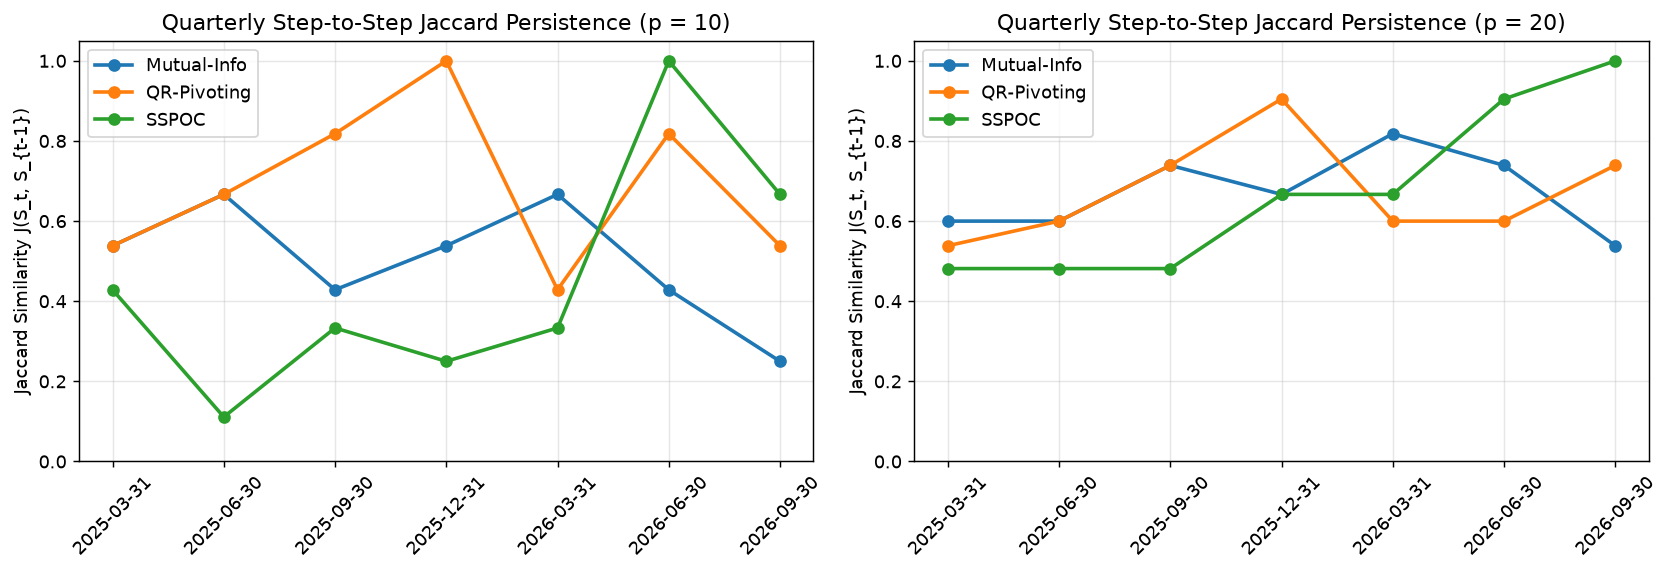

In [8]:
from sparse_sensor import run_walkforward_sensor_stability

wf = run_walkforward_sensor_stability(
    data=data,
    target_zone="N.Y.C.",
    p_budgets=(5, 10, 20),
    pod_rank=25,
    sspoc_alpha_frac=0.15,
    force_recompute=False,
)

wf_df = pd.DataFrame(wf["jaccard_records"])

# 1. Summary Table: Mean & Min Jaccard Persistence Across 2025-2026 Quarters
summary_wf = (
    wf_df.groupby(["Scheme", "p"])[["Step Jaccard (t vs t-1)", "Anchor Jaccard (t vs 2024-12)"]]
    .agg(["mean", "min"])
    .round(3)
)
print("=== Expanding Walk-Forward PTID Jaccard Persistence (2025-2026) ===")
print(summary_wf.to_markdown())

# 2. Identify Core Invariant SSPOC PTIDs (Frequency across all quarterly fits at p=10)
sspoc_hist = wf["history"]["SSPOC"]
n_quarters = len(sspoc_hist)
freq_counts = pd.Series([ptid for plist in sspoc_hist.values() for ptid in plist[:10]]).value_counts()

core_df = (
    freq_counts.rename_axis("PTID_str")
    .reset_index(name="Quarters_Selected")
    .assign(Persistence_Pct=lambda d: (d["Quarters_Selected"] / n_quarters * 100).round(1))
    .merge(gen_meta_unique, on="PTID_str", how="left")
)
keep_cols = [c for c in ["PTID_str", "Generator Name", "Zone Name", "Subzone", "Quarters_Selected", "Persistence_Pct"] if c in core_df.columns]
print(f"\n=== Core Invariant SSPOC Bellwether Nodes Across {n_quarters} Quarters (Top p=10) ===")
print(core_df[keep_cols].head(12).to_markdown(index=False))

# 3. Plot Quarterly Step-to-Step Jaccard Stability at p=10 and p=20
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=130)
for ax, p_val in zip(axes, [10, 20]):
    sub = wf_df[wf_df["p"] == p_val]
    for scheme, grp in sub.groupby("Scheme"):
        ax.plot(grp["Quarter"], grp["Step Jaccard (t vs t-1)"], marker="o", linewidth=2, label=scheme)
    ax.set_title(f"Quarterly Step-to-Step Jaccard Persistence (p = {p_val})")
    ax.set_ylabel("Jaccard Similarity J(S_t, S_{t-1})")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


## 6. Cross-Paradigm Comparison: 30-Day Scheduled Refit `SSPOC` vs. `DMDc`

In **Notebook 03 (`03_dmdc_iterative_scheduled_refit.ipynb`)**, periodic **30-day (`720h`) expanding-window refitting** enabled `DMDc` to adapt to 2025–2026 fuel and seasonal regime shifts (`+$24,111.78` Cum PnL, `3.12` Annual Sharpe). Here, we apply the **exact same 30-day expanding-window refit schedule** to **`SSPOC` ($p=20$ bellwether sensors + `Multinomial Logit`)**—using only `3.6%` of the grid's generator buses (`20/559` nodes) with zero exogenous weather/load features—and compare it head-to-head against `DMDc` on the identical `2025–2026` out-of-sample window.


In [9]:
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from tqdm import tqdm

# === 1. Locate merged_parquet & Load Nodal + Zonal Spreads ===
data_dir = Path("nyiso_data/merged_parquet").resolve()
if not data_dir.exists():
    data_dir = Path("../nyiso_data/merged_parquet").resolve()

def load_parquet_ts(path: Path) -> pd.DataFrame:
    df = pd.read_parquet(path)
    if not isinstance(df.index, pd.DatetimeIndex):
        ts_col = next(c for c in df.columns if any(k in c.lower() for k in ["time", "date", "stamp"]))
        df = df.set_index(pd.to_datetime(df[ts_col])).drop(columns=[ts_col])
    if df.index.tz is not None:
        df.index = df.index.tz_convert("America/New_York").tz_localize(None)
    return df.sort_index()

nodal_df = load_parquet_ts(data_dir / "nodal_dart_spread.parquet").ffill().bfill()
zonal_df = load_parquet_ts(data_dir / "zonal_dart_spread.parquet").ffill().bfill()

TARGET_ZONE = "N.Y.C."
CAUSAL_LAG = 48
TX_FEE = 0.50
P_BUDGET = 20

common_ts = nodal_df.index.intersection(zonal_df.index)
nodal_df = nodal_df.loc[common_ts]
y_nyc_full = zonal_df.loc[common_ts, TARGET_ZONE]

# Compute leak-free 15th/85th tail thresholds on 2020-2024 training spreads
q_low = float(y_nyc_full.loc[:"2024-12-31 23:00:00"].quantile(0.15))
q_high = float(y_nyc_full.loc[:"2024-12-31 23:00:00"].quantile(0.85))
y_cls_all = pd.Series(
    np.where(y_nyc_full > q_high, 1, np.where(y_nyc_full < q_low, -1, 0)),
    index=common_ts
)

# === 2. Evaluate 30-Day (720h) Expanding-Window Refit SSPOC (p=20 + Multinomial Logit) ===
sspoc_ptids = [str(p).replace(".0", "").strip() for p in sensors["SSPOC"]["ranked_ptids"][:P_BUDGET]]
nodal_cols_str = [str(c).replace(".0", "").strip() for c in nodal_df.columns]
col_lookup = dict(zip(nodal_cols_str, nodal_df.columns))
selected_cols = [col_lookup[p] for p in sspoc_ptids if p in col_lookup]

X_sspoc_lag48 = nodal_df[selected_cols].shift(CAUSAL_LAG).dropna()
y_cls_aligned = y_cls_all.loc[X_sspoc_lag48.index]

oos_mask = X_sspoc_lag48.index >= pd.Timestamp("2025-01-01 00:00:00")
oos_indices = np.where(oos_mask)[0]

X_mat = X_sspoc_lag48.to_numpy()
y_vec = y_cls_aligned.to_numpy()

last_fit_dec = -999
scaler_sspoc = StandardScaler()
clf_sspoc = LogisticRegression(
    solver="lbfgs",
    max_iter=500,
    C=0.5,
    class_weight="balanced",
    random_state=42,
)

sched_sspoc_sigs = []
for idx_t in tqdm(oos_indices, desc="Evaluating 30-Day Refit SSPOC (p=20)"):
    dec_idx = idx_t - CAUSAL_LAG
    if dec_idx - last_fit_dec >= 720:
        X_tr = scaler_sspoc.fit_transform(X_mat[: dec_idx + 1])
        y_tr = y_vec[: dec_idx + 1]
        clf_sspoc.fit(X_tr, y_tr)
        last_fit_dec = dec_idx

    x_te = scaler_sspoc.transform(X_mat[idx_t : idx_t + 1])
    pred_cls = int(clf_sspoc.predict(x_te)[0])
    sched_sspoc_sigs.append(pred_cls)

sspoc_sched_s = pd.Series(sched_sspoc_sigs, index=X_sspoc_lag48.index[oos_indices])

# === 3. Load DMDc Benchmarks from Notebook 2 & Align Timestamps ===
dmdc_path = data_dir / "dmdc_scheduled_oos_results.parquet"
if not dmdc_path.exists():
    raise FileNotFoundError(
        f"Missing {dmdc_path}. Run the export snippet at the end of Notebook 2 Cell 5 first."
    )

dmdc_df = pd.read_parquet(dmdc_path)
aligned_idx = dmdc_df.index.intersection(sspoc_sched_s.index)
cmp_df = dmdc_df.loc[aligned_idx].copy()

cmp_df["sig_sspoc_sched"] = sspoc_sched_s.loc[aligned_idx]
cmp_df["pnl_sspoc_sched"] = np.where(
    cmp_df["sig_sspoc_sched"] != 0,
    cmp_df["sig_sspoc_sched"] * cmp_df["realized_spread"] - TX_FEE,
    0.0,
)

true_cls_oos = np.where(
    cmp_df["realized_spread"] > q_high, 1,
    np.where(cmp_df["realized_spread"] < q_low, -1, 0)
)

def summarize_oos(sig_arr: np.ndarray, pnl_arr: np.ndarray, name: str, telemetry: str) -> dict:
    active = sig_arr != 0
    cum_pnl = np.cumsum(pnl_arr)
    max_dd = float(np.max(np.maximum.accumulate(cum_pnl) - cum_pnl))
    sharpe = float((np.mean(pnl_arr) / (np.std(pnl_arr) + 1e-8)) * np.sqrt(8760))
    win_rate = float(np.mean(pnl_arr[active] > 0) * 100) if np.any(active) else 0.0
    macro_f1 = float(f1_score(true_cls_oos, sig_arr, average="macro", zero_division=0))
    tail_f1 = float(f1_score(true_cls_oos, sig_arr, labels=[-1, 1], average="macro", zero_division=0))
    return {
        "Model": name,
        "Grid Telemetry": telemetry,
        "Cum PnL ($)": round(float(cum_pnl[-1]), 2),
        "Annual Sharpe": round(sharpe, 2),
        "Max DD ($)": round(max_dd, 2),
        "Trade Freq (%)": round(float(np.mean(active) * 100), 1),
        "Win Rate (%)": round(win_rate, 1),
        "Macro F1": round(macro_f1, 4),
        "Tail F1": round(tail_f1, 4),
    }

static_sspoc_row = metrics_df[(metrics_df["Scheme"] == "SSPOC") & (metrics_df["p"] == 20) & (metrics_df["Model"] == "Multinomial Logit")].iloc[0]

unified_rows = [
    summarize_oos(cmp_df["sig_bop"].values, cmp_df["pnl_bop"].values, "1. Unforced BOP-DMD (Static)", "15 Zones (Dense)"),
    summarize_oos(cmp_df["sig_nb1_static"].values, cmp_df["pnl_nb1_static"].values, "2. Static 48h-Jump DMDc (Frozen '24)", "15 Zones + 424 Exog"),
    summarize_oos(cmp_df["sig_dmdc_sched"].values, cmp_df["pnl_dmdc_sched"].values, "3. Scheduled 30-Day Refit DMDc (720h)", "15 Zones + 424 Exog"),
    {
        "Model": "4. Static SSPOC (p=20, Multinomial Logit)",
        "Grid Telemetry": "20/559 Buses (3.6% Sparse)",
        "Cum PnL ($)": round(float(static_sspoc_row["Cum PnL ($)"]), 2),
        "Annual Sharpe": round(float(static_sspoc_row["Annual Sharpe"]), 2),
        "Max DD ($)": round(float(static_sspoc_row["Max DD ($)"]), 2),
        "Trade Freq (%)": round(float(static_sspoc_row["Trade Freq (%)"]), 1),
        "Win Rate (%)": round(float(static_sspoc_row["Win Rate (%)"]), 1),
        "Macro F1": round(float(static_sspoc_row["Macro F1"]), 4),
        "Tail F1": round(float(static_sspoc_row["Tail F1"]), 4),
    },
    summarize_oos(cmp_df["sig_sspoc_sched"].values, cmp_df["pnl_sspoc_sched"].values, "5. Scheduled 30-Day Refit SSPOC (p=20)", "20/559 Buses (3.6% Sparse)"),
]

unified_df = pd.DataFrame(unified_rows)
print("=== Unified Cross-Paradigm Benchmark: DMDc vs. Sparse Sensor SSPOC (2025–2026 OOS) ===")
print(unified_df.to_markdown(index=False))


Evaluating 30-Day Refit SSPOC (p=20): 100%|██████████| 16306/16306 [00:09<00:00, 1716.02it/s]

=== Unified Cross-Paradigm Benchmark: DMDc vs. Sparse Sensor SSPOC (2025–2026 OOS) ===
| Model                                     | Grid Telemetry             |   Cum PnL ($) |   Annual Sharpe |   Max DD ($) |   Trade Freq (%) |   Win Rate (%) |   Macro F1 |   Tail F1 |
|:------------------------------------------|:---------------------------|--------------:|----------------:|-------------:|-----------------:|---------------:|-----------:|----------:|
| 1. Unforced BOP-DMD (Static)              | 15 Zones (Dense)           |       -985.77 |           -0.19 |      4772.75 |              1.6 |           43.2 |     0.2644 |    0.0243 |
| 2. Static 48h-Jump DMDc (Frozen '24)      | 15 Zones + 424 Exog        |        630.27 |            0.06 |     37920.7  |             58.8 |           51.4 |     0.3697 |    0.2812 |
| 3. Scheduled 30-Day Refit DMDc (720h)     | 15 Zones + 424 Exog        |      24111.8  |            3.12 |      5181.87 |             36.2 |           52.2 |     0.3714 | 

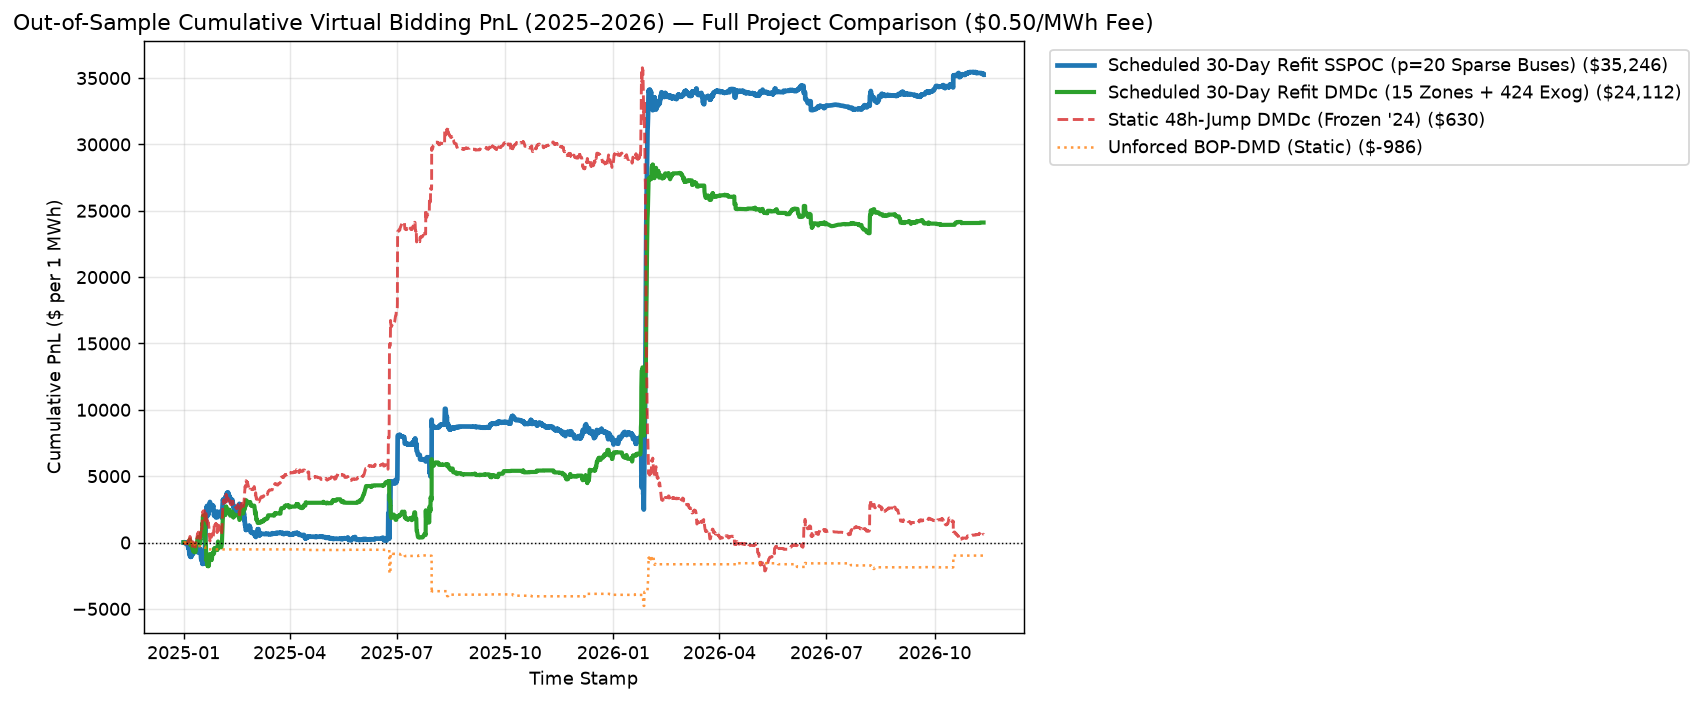

In [10]:
# === Grand Finale: Cumulative OOS PnL Across All Paradigms (Baselines + DMDc + SSPOC) ===
stage1_pnl_path = data_dir / "stage1_baseline_unit_pnl_NYC.parquet"
if not stage1_pnl_path.exists():
    stage1_pnl_path = data_dir / "stage1_baseline_unit_pnl.parquet"

stage1_pnl = pd.read_parquet(stage1_pnl_path).reindex(cmp_df.index).fillna(0.0)

# Select top reference baselines from Notebook 1 to compare against DMDc & SSPOC
top_baseline_cols = [
    c for c in [
        "Continuous Ridge Regression (Exog + 559 Nodes)",
        "Natural-Prior MLP (tau-tuned) [tau=0.24] (Exog-Only)",
        "Galarneau-Vincent et al. (2023) GBDT (Exog + 559 Nodes)",
        "Causal 48h Persistence (Target Lags)",
    ]
    if c in stage1_pnl.columns
]

grand_pnl_df = pd.DataFrame(index=cmp_df.index)
grand_pnl_df["Scheduled 30-Day Refit SSPOC (p=20 Sparse Buses)"] = cmp_df["pnl_sspoc_sched"]
grand_pnl_df["Scheduled 30-Day Refit DMDc (15 Zones + 424 Exog)"] = cmp_df["pnl_dmdc_sched"]

for col in top_baseline_cols:
    grand_pnl_df[col] = stage1_pnl[col]

grand_pnl_df["Static 48h-Jump DMDc (Frozen '24)"] = cmp_df["pnl_nb1_static"]
grand_pnl_df["Unforced BOP-DMD (Static)"] = cmp_df["pnl_bop"]

# Plot in the exact style of 01_baseline_evaluation.ipynb
fig, ax = plt.subplots(figsize=(13, 5.5), dpi=130)

styles = {
    "Scheduled 30-Day Refit SSPOC (p=20 Sparse Buses)": {"lw": 2.6, "color": "#1f77b4", "ls": "-"},
    "Scheduled 30-Day Refit DMDc (15 Zones + 424 Exog)": {"lw": 2.3, "color": "#2ca02c", "ls": "-"},
    "Static 48h-Jump DMDc (Frozen '24)": {"lw": 1.6, "color": "#d62728", "ls": "--", "alpha": 0.8},
    "Unforced BOP-DMD (Static)": {"lw": 1.4, "color": "#ff7f0e", "ls": ":", "alpha": 0.8},
}

cum_df = grand_pnl_df.cumsum()
for col in cum_df.columns:
    st = styles.get(col, {"lw": 1.4, "ls": "-.", "alpha": 0.75})
    ax.plot(cum_df.index, cum_df[col], label=f"{col} (${cum_df[col].iloc[-1]:,.0f})", **st)

ax.axhline(0, color="black", lw=0.8, ls=":")
ax.set_title("Out-of-Sample Cumulative Virtual Bidding PnL (2025–2026) — Full Project Comparison ($0.50/MWh Fee)")
ax.set_ylabel("Cumulative PnL ($ per 1 MWh)")
ax.set_xlabel("Time Stamp")
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()


In [11]:
from types import SimpleNamespace
from evaluate_models import plot_sspoc_sensors_with_interconnects

# Adapt the cached ablation sensor dictionary into the object format expected by plot_sspoc_sensors_with_interconnects
sspoc_info = sensors["SSPOC"]
ranked_ptids = [str(p).replace(".0", "").strip() for p in sspoc_info["ranked_ptids"]]
nodal_ptids = [str(c).replace(".0", "").strip() for c in data["nodal_dart"].columns]
ptid_to_idx = {p: i for i, p in enumerate(nodal_ptids)}

top20_ptids = ranked_ptids[:20]
top20_indices = [ptid_to_idx[p] for p in top20_ptids if p in ptid_to_idx]

raw_weights = sspoc_info.get("weights", sspoc_info.get("scores", None))
if raw_weights is not None and len(raw_weights) >= len(top20_indices):
    top20_weights = np.asarray(raw_weights[: len(top20_indices)], dtype=float)
else:
    top20_weights = np.linspace(1.0, 0.35, len(top20_indices))

selector_20 = SimpleNamespace(
    selected_indices_=top20_indices,
    sensor_weights_=top20_weights,
)

# Render the interactive Plotly map of the 20 optimal SSPOC sensors + cross-border interconnects
chosen_sensors_map_df = plot_sspoc_sensors_with_interconnects(
    data,
    selector_20,
    nodal_ptids,
    target_zone="N.Y.C.",
)
display(chosen_sensors_map_df[["Generator Name", "PTID_str", "Zone", "Subzone", "Sensor Weight"]].head(20))


,Generator Name,PTID_str,Zone,Subzone,Sensor Weight
399,HUNTINGTON_RES_REC,323705,LONGIL,LIPA LONG ISLAND,0.648869
527,NEG___GEN_MONROE,24207,GENESE,NMPC GENESEE,0.331659
556,NINE_MILE_2,23744,CENTRL,NMPC CENTRAL,0.311955
555,NINE_MILE_1,23575,CENTRL,NMPC CENTRAL,0.253984
386,HQ_GEN_IMPORT,323601,H Q,HQNY,0.250925
469,MAPLE_RIDGE_WT_1,323574,MHK VL,NMPC MOHAWK VLY,0.249242
470,MAPLE_RIDGE_WT_2,323611,MHK VL,NMPC MOHAWK VLY,0.249203
573,NPX_GEN_1385_PROXY,323591,NPX,NENP,0.196424
387,HQ_GEN_WHEEL,23651,H Q,HQEX,0.192695
185,CRICKET___VALLEY_CC3,323758,HUD VL,CON ED HUDSON VLY,0.170395


### Physical Grid Interpretation of the Optimal $p=20$ `SSPOC` Sensor Network

Without any prior knowledge of grid geography or transmission topology, **`SSPOC` places zero sensors inside `N.Y.C.` (Zone J)**—where internal 345 kV/138 kV prices are tightly coupled—and instead positions all 20 bellwether nodes along the **upstream congestion interfaces and cross-border tie-lines** that govern power delivery into New York City:

* **Downstate & Hudson Valley Bottlenecks (`HUD VL` & `LONGIL` — 6 sensors):** `CRICKET___VALLEY_CC1–CC3`, `SHOEMAKER___GT`, and `MONGAUP___HYD` sit directly on the **UPNY–ConEd** thermal corridor feeding Zone J, while top-weighted **`HUNTINGTON_RES_REC`** (`weight: 0.649`, `100%` walk-forward persistence) captures East-of-Hudson and submarine cable scarcity across `LIPA`.
* **Upstate Bulk Transfer Corridors (`WEST`, `GENESE`, `CENTRL`, `MHK VL` — 10 sensors):** Niagara-area nodes (`CH_RES_NIAGARA`, `PACKARD_115_KV`, `OCC_CHEM___DRP`, `OXY_CHEM_DSASP`), Genesee hydro (`NEG___GEN_MONROE`, `OAK ORCHARD___HYD`), `NINE_MILE_1 & 2`, and `MAPLE_RIDGE_WT_1 & 2` track hydro, nuclear, and wind flows across the **West–Central** and **Central–East** transfer interfaces.
* **Cross-Border External Interfaces (`H Q`, `NPX`, `PJM` — 4 sensors):** `HQ_GEN_IMPORT` and `HQ_GEN_WHEEL` monitor Hydro-Québec inflows, `NPX_GEN_1385_PROXY` tracks ISO-NE exchanges over the **1385 submarine cable**, and `PJM_GEN_VFT_PROXY` captures direct **Linden VFT** controllable injections from PJM into Zone J.

> **Note on Co-Located Plant Units:** Because standard $\ell_1$-regularized `SSPOC` applies no spatial distance penalty, it selects multiple co-located units at the highest-signal facilities (`Cricket Valley CC1–3`, `Nine Mile 1–2`, and `Maple Ridge WT 1–2`). In effect, the optimizer double- or triple-weights the most critical transmission corridors—confirming their physical importance, while highlighting group-sparse ($\ell_{2,1}$) sensor selection as a natural extension if strict geographic separation is required.


## Summary of Key Findings (`SSPOC` Sparse Sensing & `DMDc` Synthesis)

1. **Task-Driven Sensing Beats Whole-Grid Reconstruction (`96.4%` Sensor Reduction):**
   - `QR-Pivoting` excels at reconstructing the entire 559-bus grid (`Grid R² = 0.945` at $p=40$ vs. `0.196` for `SSPOC`), whereas `Mutual-Info` clusters redundantly inside `N.Y.C.` (`10/20` nodes in Zone J) and degrades as $p$ increases (`Grid R² = -0.229` at $p=40$).
   - By optimizing directly for 3-class tail separation in the rank-25 POD subspace, **Static `SSPOC` with just $p=20$ sensors (`3.6%` of the grid)** paired with `Multinomial Logit` achieves **`1.95` Annual Sharpe (`+$21,455.70` Cum PnL, `0.3085` Tail F1, `$13,173.60` Max DD)**—outperforming the full 559-node `Multinomial Logit` baseline (`1.78` Sharpe, `+$19,539.42` Cum PnL) while cutting Max Drawdown by `30%`.

2. **Physical Transmission Bottleneck Discovery:**
   - Rather than placing sensors inside `N.Y.C.` (`0/20` nodes in Zone J), `SSPOC` selects upstream interface and bottleneck generators across **`HUD VL` (`5` nodes, e.g., Cricket Valley CC1–CC3, Shoemaker GT)**, **`WEST` (`4` nodes, e.g., Niagara / Packard)**, **`CENTRL` (`2` nodes, Nine Mile 1 & 2)**, **`MHK VL` (`2` nodes, Maple Ridge Wind)**, **`LONGIL` (`1` node, Huntington Res Rec)**, and external import proxies (**`H Q`**, **`NPX`**, **`PJM-VFT`**).
   - When the target zone shifts to **`LONGIL`** (`2.41` Sharpe at $p=20$) or **`HUD VL`** (`4.04` Sharpe at $p=20$), `SSPOC` automatically re-anchors its top bellwether sensors to each zone's local radial and interface constraints.

3. **Temporal Persistence Across Out-of-Sample Regimes (`2025–2026`):**
   - Under quarterly expanding walk-forward retraining across `2025–2026`, `SSPOC` achieves a **`0.669` mean step-to-step Jaccard similarity** at $p=20$ and isolates a core set of structurally invariant grid sensors—led by **`HUNTINGTON_RES_REC` (`100%` quarterly persistence)**, **`NINE_MILE_2` (`87.5%`)**, **`NINE_MILE_1` (`75.0%`)**, **`CH_RES_BVR_FALLS` (`75.0%`)**, and **`CRICKET___VALLEY_CC3` (`62.5%`)**.

4. **Cross-Paradigm Synthesis (`Scheduled 30-Day Refit SSPOC` vs. `DMDc`):**
   - Applying **30-day (`720h`) scheduled expanding-window refitting**—motivated by **Notebooks 02 & 03's** regime-drift analysis—boosts `SSPOC` ($p=20$) from **`1.95` to `3.56` Annual Sharpe**, increases Cumulative PnL from **`+$21,455.70` to `+$35,246.10`**, improves Macro F1 from **`0.3732` to `0.4167`**, and cuts Max Drawdown by **`42%`** (`$13,173.60` $\rightarrow$ `$7,595.29`).
   - Across all evaluated paradigms on the `2025–2026` out-of-sample period, **`Scheduled 30-Day Refit SSPOC (p=20)`** (`3.56` Sharpe, `+$35,246.10` Cum PnL, `0.2953` Tail F1) outperforms **`Scheduled 30-Day Refit DMDc`** (`3.12` Sharpe, `+$24,111.80` Cum PnL, `0.2312` Tail F1) while requiring **only 20 sparse generator buses (`3.6%` of the grid) and zero exogenous weather/load telemetry**.
